## 1. Load and inspect the Nigeria HarvestStat data

We load the prepared Nigeria dataset and inspect its size, columns, and first rows. This confirms the notebook is reading the file we just checked before we begin exploring its patterns.

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/processed/harveststat_nigeria.csv")
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nData types and non-missing counts:")
df.info()

Dataset shape: (9636, 16)

Columns:
['fnid', 'country', 'country_code', 'admin_1', 'admin_2', 'product', 'season_name', 'planting_year', 'planting_month', 'harvest_year', 'harvest_month', 'crop_production_system', 'qc_flag', 'area', 'production', 'yield']

First five rows:


,fnid,country,country_code,admin_1,admin_2,product,season_name,planting_year,planting_month,harvest_year,harvest_month,crop_production_system,qc_flag,area,production,yield
0,NG1996A101,Nigeria,NG,Abia,none,Banana,Wet,2019,3,2019,10,All (PS),0,16700.0,138300.0,8.281437
1,NG1996A101,Nigeria,NG,Abia,none,Banana,Wet,2020,3,2020,10,All (PS),0,18800.0,139000.0,7.393617
2,NG1996A101,Nigeria,NG,Abia,none,Banana,Wet,2021,3,2021,10,All (PS),0,18800.0,139000.0,7.393617
3,NG1996A101,Nigeria,NG,Abia,none,Cassava,Annual,1999,3,1999,10,All (PS),0,19760.0,346800.0,17.550607
4,NG1996A101,Nigeria,NG,Abia,none,Cassava,Annual,2000,3,2000,10,All (PS),0,14290.0,250000.0,17.494752



Data types and non-missing counts:
<class 'pandas.DataFrame'>
RangeIndex: 9636 entries, 0 to 9635
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   fnid                    9636 non-null   str    
 1   country                 9636 non-null   str    
 2   country_code            9636 non-null   str    
 3   admin_1                 9636 non-null   str    
 4   admin_2                 9636 non-null   str    
 5   product                 9636 non-null   str    
 6   season_name             9636 non-null   str    
 7   planting_year           9636 non-null   int64  
 8   planting_month          9636 non-null   int64  
 9   harvest_year            9636 non-null   int64  
 10  harvest_month           9636 non-null   int64  
 11  crop_production_system  9636 non-null   str    
 12  qc_flag                 9636 non-null   int64  
 13  area                    9111 non-null   float64
 14  production     

## 2. Explore crop, time, and geographic coverage

We summarize how many records and valid yields are available for each crop, the year range represented, and the number of first-level regions covered. We also inspect season, calendar-month, and QC-flag values. These summaries will help us choose crops and understand coverage before making plots or modeling decisions.

In [2]:
print("Harvest year range:", df["harvest_year"].min(), "to", df["harvest_year"].max())
print("Number of crops:", df["product"].nunique())
print("Number of first-level regions:", df["admin_1"].nunique())
print("admin_2 values:", df["admin_2"].value_counts(dropna=False).to_dict())

crop_summary = (
    df.groupby("product")
    .agg(
        records=("product", "size"),
        valid_yield=("yield", "count"),
        first_harvest_year=("harvest_year", "min"),
        last_harvest_year=("harvest_year", "max"),
        regions=("admin_1", "nunique"),
    )
    .sort_values("records", ascending=False)
)

display(crop_summary)
print("\nSeason counts:")
display(df["season_name"].value_counts(dropna=False))

print("\nPlanting-month counts:")
display(df["planting_month"].value_counts(dropna=False).sort_index())

print("\nHarvest-month counts:")
display(df["harvest_month"].value_counts(dropna=False).sort_index())

print("\nQC-flag counts:")
display(df["qc_flag"].value_counts(dropna=False).sort_index())

Harvest year range: 1999 to 2023
Number of crops: 20
Number of first-level regions: 37
admin_2 values: {'none': 9636}


,records,valid_yield,first_harvest_year,last_harvest_year,regions
product,,,,,
Maize,919,919,1999,2023,37
Rice,909,906,1999,2023,37
Cowpea,861,838,1999,2023,37
Cassava,851,844,1999,2023,37
Groundnuts (In Shell),782,768,1999,2023,36
Yams,697,694,1999,2023,30
Taro,612,550,1999,2021,33
Sorghum,536,536,1999,2023,27
Millet,512,499,1999,2023,26



Season counts:


season_name
Wet       7478
Annual    2158
Name: count, dtype: int64


Planting-month counts:


planting_month
3    9636
Name: count, dtype: int64


Harvest-month counts:


harvest_month
10    9636
Name: count, dtype: int64


QC-flag counts:


qc_flag
0    9020
1      18
2     598
Name: count, dtype: int64

In [3]:
print(crop_summary.to_string())

                       records  valid_yield  first_harvest_year  last_harvest_year  regions
product                                                                                    
Maize                      919          919                1999               2023       37
Rice                       909          906                1999               2023       37
Cowpea                     861          838                1999               2023       37
Cassava                    851          844                1999               2023       37
Groundnuts (In Shell)      782          768                1999               2023       36
Yams                       697          694                1999               2023       30
Taro                       612          550                1999               2021       33
Sorghum                    536          536                1999               2023       27
Millet                     512          499                1999               20

## 3. Inspect yield distributions for well-covered crops

We plot yields separately for crops with stronger data coverage. Each crop gets its own y-axis because yield scales differ between crops. These plots help us spot skewed distributions and values that deserve review. Boxplot outliers are review prompts, not automatic errors, so we retain all observations at this stage.

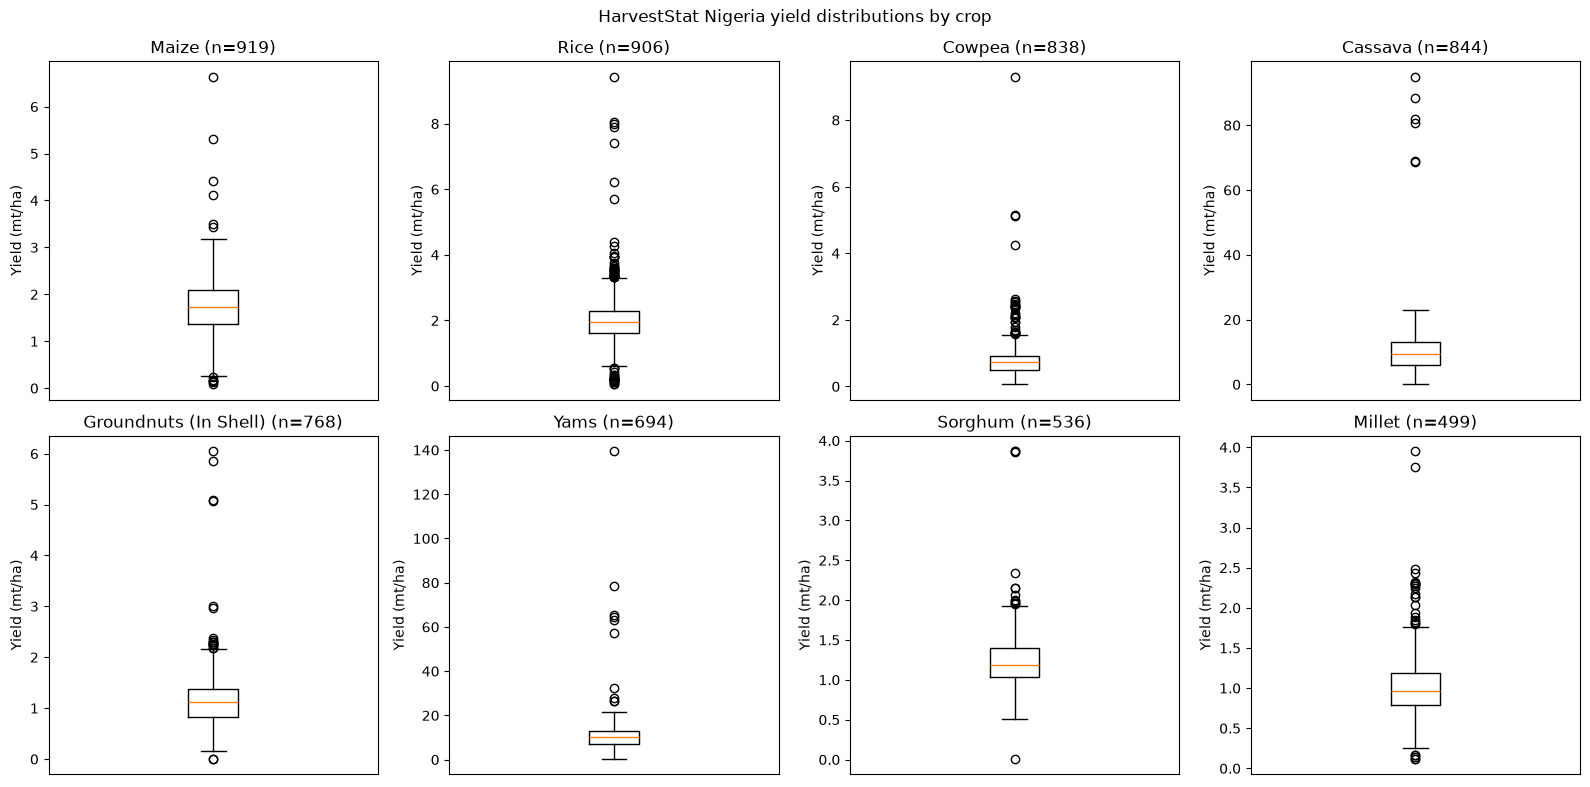

In [4]:
import matplotlib.pyplot as plt

candidate_crops = [
    "Maize", "Rice", "Cowpea", "Cassava",
    "Groundnuts (In Shell)", "Yams", "Sorghum", "Millet",
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=False)

for ax, crop in zip(axes.flat, candidate_crops):
    values = df.loc[df["product"].eq(crop), "yield"].dropna()
    ax.boxplot(values, showfliers=True)
    ax.set_title(f"{crop} (n={len(values)})")
    ax.set_ylabel("Yield (mt/ha)")
    ax.set_xticks([])

fig.suptitle("HarvestStat Nigeria yield distributions by crop")
fig.tight_layout()
plt.show()

## 4. Review unusually high yields

A boxplot marks values beyond 1.5 times the interquartile range as statistical outliers. We calculate that threshold separately for each crop and inspect the highest flagged observations alongside their source fields and HarvestStat QC flags. These flags are prompts for investigation; we do not remove or change records based on them alone.

In [5]:
review_data = df.loc[
    df["product"].isin(candidate_crops) & df["yield"].notna()
].copy()

quartiles = (
    review_data.groupby("product")["yield"]
    .quantile([0.25, 0.75])
    .unstack()
    .rename(columns={0.25: "q1", 0.75: "q3"})
)

quartiles["upper_bound"] = quartiles["q3"] + 1.5 * (
    quartiles["q3"] - quartiles["q1"]
)

review_data = review_data.join(quartiles[["upper_bound"]], on="product")
review_data["high_yield_review"] = (
    review_data["yield"] > review_data["upper_bound"]
)

print("High-yield review counts by crop:")
display(
    review_data.groupby("product")["high_yield_review"]
    .sum()
    .sort_values(ascending=False)
    .rename("high_yield_review_count")
    .to_frame()
)

review_columns = [
    "product", "admin_1", "harvest_year", "season_name",
    "yield", "production", "area", "qc_flag",
]

highest_reviews = (
    review_data.loc[review_data["high_yield_review"]]
    .sort_values(["product", "yield"], ascending=[True, False])
    .groupby("product")
    .head(3)
)

display(highest_reviews[review_columns].sort_values("yield", ascending=False))

High-yield review counts by crop:


,high_yield_review_count
product,
Rice,38
Cowpea,30
Millet,21
Groundnuts (In Shell),18
Sorghum,12
Yams,10
Cassava,6
Maize,6


,product,admin_1,harvest_year,season_name,yield,production,area,qc_flag
3288,Yams,Enugu,2010,Annual,139.382239,3249000.0,23310.0,1
1398,Cassava,Benue,2012,Annual,94.966407,3663804.0,38580.0,1
1397,Cassava,Benue,2011,Annual,88.368114,3663742.0,41460.0,0
6426,Cassava,Nasarawa,2012,Annual,81.839868,1486212.0,18160.0,1
2173,Yams,Cross River,2010,Annual,78.438957,3398760.0,43330.0,1
6150,Yams,Kwara,2010,Annual,65.486383,5314220.0,81150.0,0
2739,Rice,Edo,2012,Wet,9.431072,129300.0,13710.0,1
4408,Cowpea,Kaduna,2007,Wet,9.301408,330200.0,35500.0,1
5719,Rice,Kogi,2011,Wet,8.050378,490429.0,60920.0,0
5718,Rice,Kogi,2010,Wet,7.998736,480804.0,60110.0,0


## 5. Compare high-yield records with nearby years

For the highest review candidates, we compare the same crop, region, and season over a five-year window. We inspect yield, production, area, and the source QC flag. This provides context for follow-up; unusual values are not removed or changed automatically.

In [6]:
case_keys = [
    "product", "admin_1", "harvest_year", "season_name"
]

top_cases = (
    highest_reviews.sort_values("yield", ascending=False)
    .drop_duplicates(subset=case_keys)
    .head(6)
)

context_parts = []

for _, case in top_cases.iterrows():
    same_series = (
        df["product"].eq(case["product"])
        & df["admin_1"].eq(case["admin_1"])
        & df["season_name"].eq(case["season_name"])
        & df["harvest_year"].between(
            case["harvest_year"] - 2,
            case["harvest_year"] + 2,
        )
    )
    context_parts.append(df.loc[same_series])

context = (
    pd.concat(context_parts)
    .drop_duplicates()
    .sort_values(["product", "admin_1", "season_name", "harvest_year"])
)

context_columns = [
    "product", "admin_1", "harvest_year", "season_name",
    "crop_production_system", "yield", "production", "area", "qc_flag",
]

display(context[context_columns])

,product,admin_1,harvest_year,season_name,crop_production_system,yield,production,area,qc_flag
1395,Cassava,Benue,2009,Annual,All (PS),13.200236,3584260.0,271530.0,2
1396,Cassava,Benue,2010,Annual,All (PS),13.299964,3661480.0,275300.0,2
1397,Cassava,Benue,2011,Annual,All (PS),88.368114,3663742.0,41460.0,0
1398,Cassava,Benue,2012,Annual,All (PS),94.966407,3663804.0,38580.0,1
1399,Cassava,Benue,2013,Annual,All (PS),10.896300,3763800.0,345420.0,0
1400,Cassava,Benue,2014,Annual,All (PS),18.680040,3724800.0,199400.0,0
6424,Cassava,Nasarawa,2010,Annual,All (PS),10.566586,1480590.0,140120.0,0
6425,Cassava,Nasarawa,2011,Annual,All (PS),80.577766,1485854.0,18440.0,0
6426,Cassava,Nasarawa,2012,Annual,All (PS),81.839868,1486212.0,18160.0,1
6427,Cassava,Nasarawa,2013,Annual,All (PS),9.524044,386200.0,40550.0,0


In [7]:
print(context[context_columns].to_string(index=False))

product     admin_1  harvest_year season_name crop_production_system      yield  production     area  qc_flag
Cassava       Benue          2009      Annual               All (PS)  13.200236   3584260.0 271530.0        2
Cassava       Benue          2010      Annual               All (PS)  13.299964   3661480.0 275300.0        2
Cassava       Benue          2011      Annual               All (PS)  88.368114   3663742.0  41460.0        0
Cassava       Benue          2012      Annual               All (PS)  94.966407   3663804.0  38580.0        1
Cassava       Benue          2013      Annual               All (PS)  10.896300   3763800.0 345420.0        0
Cassava       Benue          2014      Annual               All (PS)  18.680040   3724800.0 199400.0        0
Cassava    Nasarawa          2010      Annual               All (PS)  10.566586   1480590.0 140120.0        0
Cassava    Nasarawa          2011      Annual               All (PS)  80.577766   1485854.0  18440.0        0
Cassava   

## 6. Compare year-to-year changes in reviewed records

We calculate percentage changes in production, area, and yield between consecutive available observations for the selected crop-region series. Large changes help identify records that may need source verification. They are not automatic deletion or correction rules.

In [8]:
context_changes = context.sort_values(
    ["product", "admin_1", "season_name", "crop_production_system", "harvest_year"]
).copy()

series_keys = [
    "product", "admin_1", "season_name", "crop_production_system"
]

context_changes["previous_year"] = (
    context_changes.groupby(series_keys)["harvest_year"].shift(1)
)

for column in ["production", "area", "yield"]:
    context_changes[f"{column}_pct_change"] = (
        context_changes.groupby(series_keys)[column].pct_change() * 100
    )

change_columns = [
    "product", "admin_1", "previous_year", "harvest_year",
    "production", "production_pct_change",
    "area", "area_pct_change",
    "yield", "yield_pct_change", "qc_flag",
]

display(context_changes[change_columns].round(2))

,product,admin_1,previous_year,harvest_year,production,production_pct_change,area,area_pct_change,yield,yield_pct_change,qc_flag
1395,Cassava,Benue,NaN,2009,3584260.0,NaN,271530.0,NaN,13.20,NaN,2
1396,Cassava,Benue,2009.0,2010,3661480.0,2.15,275300.0,1.39,13.30,0.76,2
1397,Cassava,Benue,2010.0,2011,3663742.0,0.06,41460.0,-84.94,88.37,564.42,0
1398,Cassava,Benue,2011.0,2012,3663804.0,0.00,38580.0,-6.95,94.97,7.47,1
1399,Cassava,Benue,2012.0,2013,3763800.0,2.73,345420.0,795.33,10.90,-88.53,0
1400,Cassava,Benue,2013.0,2014,3724800.0,-1.04,199400.0,-42.27,18.68,71.43,0
6424,Cassava,Nasarawa,NaN,2010,1480590.0,NaN,140120.0,NaN,10.57,NaN,0
6425,Cassava,Nasarawa,2010.0,2011,1485854.0,0.36,18440.0,-86.84,80.58,662.57,0
6426,Cassava,Nasarawa,2011.0,2012,1486212.0,0.02,18160.0,-1.52,81.84,1.57,1
6427,Cassava,Nasarawa,2012.0,2013,386200.0,-74.01,40550.0,123.29,9.52,-88.36,0


In [9]:
print(context_changes[change_columns].round(2).to_string(index=False))


product     admin_1  previous_year  harvest_year  production  production_pct_change     area  area_pct_change  yield  yield_pct_change  qc_flag
Cassava       Benue            NaN          2009   3584260.0                    NaN 271530.0              NaN  13.20               NaN        2
Cassava       Benue         2009.0          2010   3661480.0                   2.15 275300.0             1.39  13.30              0.76        2
Cassava       Benue         2010.0          2011   3663742.0                   0.06  41460.0           -84.94  88.37            564.42        0
Cassava       Benue         2011.0          2012   3663804.0                   0.00  38580.0            -6.95  94.97              7.47        1
Cassava       Benue         2012.0          2013   3763800.0                   2.73 345420.0           795.33  10.90            -88.53        0
Cassava       Benue         2013.0          2014   3724800.0                  -1.04 199400.0           -42.27  18.68             71.43  

## Next, we want to check how missing values and QC flags are distributed across the eight shortlisted crops. This compares data completeness and source flags without filtering records

In [10]:
candidate_data = df.loc[df["product"].isin(candidate_crops)].copy()

print("QC flag counts by crop:")
display(pd.crosstab(candidate_data["product"], candidate_data["qc_flag"]))

missing_by_crop = (
    candidate_data.groupby("product")
    .agg(
        records=("product", "size"),
        missing_yield=("yield", lambda s: s.isna().sum()),
        missing_area=("area", lambda s: s.isna().sum()),
        missing_production=("production", lambda s: s.isna().sum()),
    )
    .sort_values("records", ascending=False)
)

print("Missing values by crop:")
display(missing_by_crop)

QC flag counts by crop:


qc_flag,0,1,2
product,,,
Cassava,747,3,101
Cowpea,824,4,33
Groundnuts (In Shell),734,0,48
Maize,846,1,72
Millet,486,1,25
Rice,872,3,34
Sorghum,492,0,44
Yams,628,4,65


Missing values by crop:


,records,missing_yield,missing_area,missing_production
product,,,,
Maize,919,0,0,0
Rice,909,3,1,2
Cowpea,861,23,14,9
Cassava,851,7,4,3
Groundnuts (In Shell),782,14,9,5
Yams,697,3,3,0
Sorghum,536,0,0,0
Millet,512,13,0,13


## 7. Check crop coverage by season

We summarize record counts, valid yields, year spans, and region coverage separately for each crop and season. We keep seasons separate because their observations may represent different reporting periods.

In [11]:
season_coverage = (
    candidate_data.groupby(["product", "season_name"])
    .agg(
        records=("product", "size"),
        valid_yield=("yield", "count"),
        first_harvest_year=("harvest_year", "min"),
        last_harvest_year=("harvest_year", "max"),
        regions=("admin_1", "nunique"),
    )
    .reset_index()
    .sort_values(["product", "season_name"])
)

display(season_coverage)

,product,season_name,records,valid_yield,first_harvest_year,last_harvest_year,regions
0,Cassava,Annual,849,842,1999,2023,37
1,Cassava,Wet,2,2,2022,2023,1
2,Cowpea,Wet,861,838,1999,2023,37
3,Groundnuts (In Shell),Wet,782,768,1999,2023,36
4,Maize,Wet,919,919,1999,2023,37
5,Millet,Wet,512,499,1999,2023,26
6,Rice,Wet,909,906,1999,2023,37
7,Sorghum,Wet,536,536,1999,2023,27
8,Yams,Annual,697,694,1999,2023,30


In [12]:
print(season_coverage.to_string(index=False))

              product season_name  records  valid_yield  first_harvest_year  last_harvest_year  regions
              Cassava      Annual      849          842                1999               2023       37
              Cassava         Wet        2            2                2022               2023        1
               Cowpea         Wet      861          838                1999               2023       37
Groundnuts (In Shell)         Wet      782          768                1999               2023       36
                Maize         Wet      919          919                1999               2023       37
               Millet         Wet      512          499                1999               2023       26
                 Rice         Wet      909          906                1999               2023       37
              Sorghum         Wet      536          536                1999               2023       27
                 Yams      Annual      697          694         

## 8. Check yearly coverage by crop and season

We count valid yields for each crop-season combination in each harvest year. This shows gaps and how much data is available in later years, which we need to plan a time-based model evaluation.

In [13]:
year_coverage = (
    candidate_data.groupby(["product", "season_name", "harvest_year"])
    .agg(
        valid_yield=("yield", "count"),
        regions=("admin_1", "nunique"),
    )
    .reset_index()
)

year_pivot = year_coverage.pivot_table(
    index=["product", "season_name"],
    columns="harvest_year",
    values="valid_yield",
    fill_value=0,
    aggfunc="sum",
).astype(int)

display(year_pivot)

harvest_year                       1999  2000  2001  2002  2003  2004  2005  \
product               season_name                                             
Cassava               Annual         31    32    32    32    32    31    35   
                      Wet             0     0     0     0     0     0     0   
Cowpea                Wet            32    33    33    33    32    30    30   
Groundnuts (In Shell) Wet            33    34    34    33    33    31    30   
Maize                 Wet            37    37    37    37    37    36    36   
Millet                Wet            20    20    20    20    20    20    19   
Rice                  Wet            35    36    37    36    36    35    34   
Sorghum               Wet            21    21    21    21    21    21    20   
Yams                  Annual         28    28    28    28    28    28    27   

harvest_year                       2006  2007  2008  ...  2014  2015  2016  \
product               season_name                    ...                     
Cassava               Annual         35    35    32  ...    36    36    36   
                      Wet             0     0     0  ...     0     0     0   
Cowpea                Wet            32    29    29  ...    36    37    37   
Groundnuts (In Shell) Wet            30    29    29  ...    32    33    33   
Maize                 Wet            36    36    36  ...    37    37    37   
Millet                Wet            19    19    21  ...    20    20    20   
Rice                  Wet            34    34    35  ...    37    37    37   
Sorghum               Wet            20    20    21  ...    20    20    24   
Yams                  Annual         28    29    28  ...    28    28    28   

harvest_year                       2017  2018  2019  2020  2021  2022  2023  
product               season_name                                            
Cassava               Annual         36    34    34    34    34    33    33  
                      Wet             0     0     0     0     0     1     1  
Cowpea                Wet            37    37    37    37    37    37    37  
Groundnuts (In Shell) Wet            33    28    28    29    29    29    29  
Maize                 Wet            37    37    37    37    37    37    37  
Millet                Wet            20    20    20    20    20    20    20  
Rice                  Wet            37    37    37    37    37    37    37  
Sorghum               Wet            24    22    22    22    22    22    22  
Yams                  Annual         28    27    26    26    26    26    26  

[9 rows x 25 columns]

In [14]:
print(year_pivot.to_string(index=False))

 1999  2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023
   31    32    32    32    32    31    35    35    35    32    34    34    33    33    35    36    36    36    36    34    34    34    34    33    33
    0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     0     1     1
   32    33    33    33    32    30    30    32    29    29    31    32    30    28    35    36    37    37    37    37    37    37    37    37    37
   33    34    34    33    33    31    30    30    29    29    30    28    30    30    31    32    33    33    33    28    28    29    29    29    29
   37    37    37    37    37    36    36    36    36    36    37    37    37    37    36    37    37    37    37    37    37    37    37    37    37
   20    20    20    20    20    20    19    19    19    21    21    20    20    20    20    20    2

## 9. Explore yield trends by year

We plot the median yield for each crop and harvest year, keeping each crop’s dominant season. Medians reduce the influence of extreme values while we inspect broad patterns. This is descriptive exploration; it does not establish that climate caused a yield change.

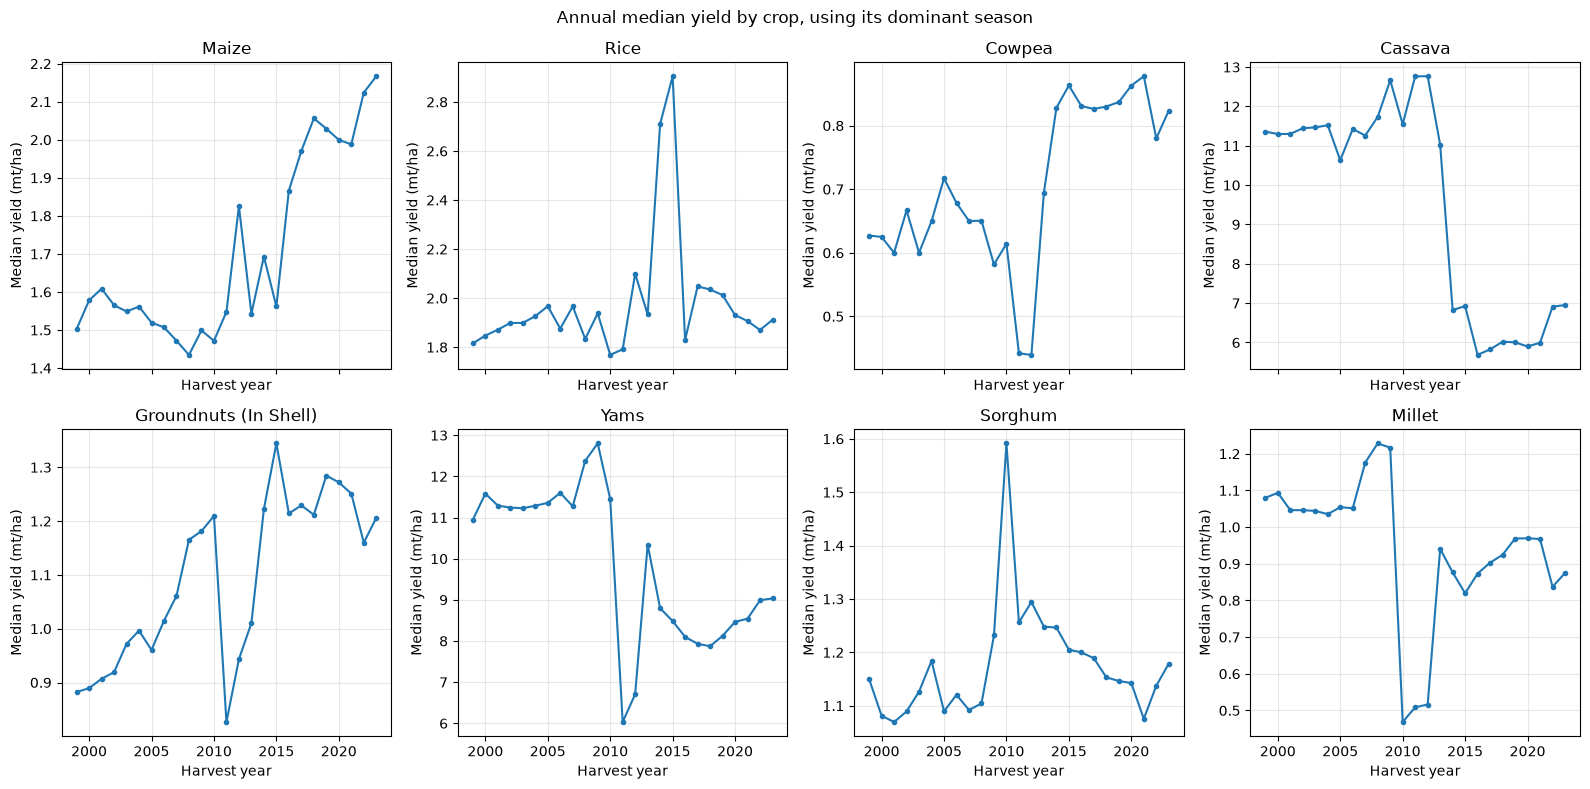

In [15]:
main_season = {
    "Cassava": "Annual",
    "Cowpea": "Wet",
    "Groundnuts (In Shell)": "Wet",
    "Maize": "Wet",
    "Millet": "Wet",
    "Rice": "Wet",
    "Sorghum": "Wet",
    "Yams": "Annual",
}

trend_data = candidate_data.copy()
trend_data["main_season"] = trend_data["product"].map(main_season)

trend_data = trend_data.loc[
    trend_data["season_name"].eq(trend_data["main_season"])
    & trend_data["yield"].notna()
]

annual_trend = (
    trend_data.groupby(["product", "harvest_year"])
    .agg(
        median_yield=("yield", "median"),
        valid_yields=("yield", "count"),
        regions=("admin_1", "nunique"),
    )
    .reset_index()
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True)

for ax, crop in zip(axes.flat, candidate_crops):
    crop_trend = annual_trend.loc[
        annual_trend["product"].eq(crop)
    ].sort_values("harvest_year")

    ax.plot(
        crop_trend["harvest_year"],
        crop_trend["median_yield"],
        marker="o",
        markersize=3,
    )
    ax.set_title(crop)
    ax.set_ylabel("Median yield (mt/ha)")
    ax.set_xlabel("Harvest year")
    ax.grid(True, alpha=0.3)

fig.suptitle("Annual median yield by crop, using its dominant season")
fig.tight_layout()
plt.show()

## 10. Check coverage around visible yield shifts

Several crop-level median yields change around 2010–2013. We check the number of valid yield records and regions represented in those years to see whether changes in coverage might contribute to the pattern.

In [16]:
coverage_check = (
    annual_trend.loc[
        annual_trend["harvest_year"].between(2008, 2016),
        ["product", "harvest_year", "valid_yields", "regions"],
    ]
    .sort_values(["product", "harvest_year"])
)

display(coverage_check)

,product,harvest_year,valid_yields,regions
9,Cassava,2008,32,32
10,Cassava,2009,34,34
11,Cassava,2010,34,34
12,Cassava,2011,33,33
13,Cassava,2012,33,33
...,...,...,...,...
188,Yams,2012,30,30
189,Yams,2013,28,28
190,Yams,2014,28,28
191,Yams,2015,28,28


In [17]:
print(coverage_check.to_string(index=False))

              product  harvest_year  valid_yields  regions
              Cassava          2008            32       32
              Cassava          2009            34       34
              Cassava          2010            34       34
              Cassava          2011            33       33
              Cassava          2012            33       33
              Cassava          2013            35       35
              Cassava          2014            36       36
              Cassava          2015            36       36
              Cassava          2016            36       36
               Cowpea          2008            29       29
               Cowpea          2009            31       31
               Cowpea          2010            32       32
               Cowpea          2011            30       30
               Cowpea          2012            28       28
               Cowpea          2013            35       35
               Cowpea          2014            36       

In [18]:
regions_pivot = coverage_check.pivot(
    index="product",
    columns="harvest_year",
    values="regions",
)

display(regions_pivot)

harvest_year,2008,2009,2010,2011,2012,2013,2014,2015,2016
product,,,,,,,,,
Cassava,32,34,34,33,33,35,36,36,36
Cowpea,29,31,32,30,28,35,36,37,37
Groundnuts (In Shell),29,30,28,30,30,31,32,33,33
Maize,36,37,37,37,37,36,37,37,37
Millet,21,21,20,20,20,20,20,20,20
Rice,35,36,37,37,37,37,37,37,37
Sorghum,21,21,21,21,25,21,20,20,24
Yams,28,29,29,29,30,28,28,28,28


In [19]:
print(regions_pivot.to_string(index=False))

 2008  2009  2010  2011  2012  2013  2014  2015  2016
   32    34    34    33    33    35    36    36    36
   29    31    32    30    28    35    36    37    37
   29    30    28    30    30    31    32    33    33
   36    37    37    37    37    36    37    37    37
   21    21    20    20    20    20    20    20    20
   35    36    37    37    37    37    37    37    37
   21    21    21    21    25    21    20    20    24
   28    29    29    29    30    28    28    28    28


## 11. Compare yield changes within the same regions

We compare selected year-to-year shifts using only regions with valid yields in both years. This helps separate changes in region coverage from changes within the regions represented in both years. It does not establish the cause of a yield change.

In [20]:
breaks = [
    ("Cassava", 2013, 2014),
    ("Cowpea", 2012, 2013),
    ("Groundnuts (In Shell)", 2010, 2011),
    ("Millet", 2009, 2010),
    ("Rice", 2013, 2014),
    ("Sorghum", 2009, 2010),
    ("Yams", 2010, 2011),
]

paired_summaries = []

for crop, year_before, year_after in breaks:
    crop_data = trend_data.loc[trend_data["product"].eq(crop)]

    before = crop_data.loc[
        crop_data["harvest_year"].eq(year_before)
    ]
    after = crop_data.loc[
        crop_data["harvest_year"].eq(year_after)
    ]

    state_yields = crop_data.pivot_table(
        index="admin_1",
        columns="harvest_year",
        values="yield",
        aggfunc="median",
    )

    common = state_yields[[year_before, year_after]].dropna()

    paired_summaries.append({
        "crop": crop,
        "years": f"{year_before} to {year_after}",
        "regions_before": before["admin_1"].nunique(),
        "regions_after": after["admin_1"].nunique(),
        "common_regions": len(common),
        "all_regions_median_before": before["yield"].median(),
        "all_regions_median_after": after["yield"].median(),
        "common_regions_median_before": common[year_before].median(),
        "common_regions_median_after": common[year_after].median(),
    })

paired_summary = pd.DataFrame(paired_summaries)
display(paired_summary.round(2))

,crop,years,regions_before,regions_after,common_regions,all_regions_median_before,all_regions_median_after,common_regions_median_before,common_regions_median_after
0,Cassava,2013 to 2014,35,36,35,11.03,6.83,11.03,6.57
1,Cowpea,2012 to 2013,28,35,28,0.44,0.69,0.44,0.77
2,Groundnuts (In Shell),2010 to 2011,28,30,27,1.21,0.83,1.25,0.91
3,Millet,2009 to 2010,21,20,20,1.22,0.47,1.22,0.47
4,Rice,2013 to 2014,37,37,37,1.93,2.71,1.93,2.71
5,Sorghum,2009 to 2010,21,21,21,1.23,1.59,1.23,1.59
6,Yams,2010 to 2011,29,29,29,11.45,6.03,11.45,6.03


In [21]:
print(paired_summary.to_string(index=False))

                 crop        years  regions_before  regions_after  common_regions  all_regions_median_before  all_regions_median_after  common_regions_median_before  common_regions_median_after
              Cassava 2013 to 2014              35             36              35                  11.028319                  6.825152                     11.028319                     6.568193
               Cowpea 2012 to 2013              28             35              28                   0.439429                  0.694767                      0.439429                     0.769269
Groundnuts (In Shell) 2010 to 2011              28             30              27                   1.209479                  0.826580                      1.248322                     0.910632
               Millet 2009 to 2010              21             20              20                   1.216510                  0.468478                      1.224595                     0.468478
                 Rice 2013 to 

## 12. Check regional changes behind yield shifts

For selected year-to-year changes, we calculate the yield percentage change within each region represented in both years. We summarize how many regions increased or decreased and the median regional change. This helps show whether the overall shift was broad or concentrated.

In [22]:
regional_change_rows = []

for crop, year_before, year_after in breaks:
    crop_data = trend_data.loc[trend_data["product"].eq(crop)]

    state_yields = crop_data.pivot_table(
        index="admin_1",
        columns="harvest_year",
        values="yield",
        aggfunc="median",
    )

    paired = state_yields[[year_before, year_after]].dropna()
    pct_change = (
        (paired[year_after] / paired[year_before] - 1) * 100
    )

    regional_change_rows.append({
        "crop": crop,
        "transition": f"{year_before} to {year_after}",
        "paired_regions": len(paired),
        "regions_increased": int((pct_change > 0).sum()),
        "regions_decreased": int((pct_change < 0).sum()),
        "median_regional_change_pct": pct_change.median(),
        "10th_percentile_pct": pct_change.quantile(0.10),
        "90th_percentile_pct": pct_change.quantile(0.90),
    })

regional_change_summary = pd.DataFrame(regional_change_rows)
print(regional_change_summary.round(1).to_string(index=False))

                 crop   transition  paired_regions  regions_increased  regions_decreased  median_regional_change_pct  10th_percentile_pct  90th_percentile_pct
              Cassava 2013 to 2014              35                 10                 25                       -21.2                -61.4                 70.2
               Cowpea 2012 to 2013              28                 21                  7                        52.8                -51.4                352.1
Groundnuts (In Shell) 2010 to 2011              27                 13                 13                         0.0                -59.0                 66.5
               Millet 2009 to 2010              20                  4                 16                       -52.8                -74.8                  4.9
                 Rice 2013 to 2014              37                 31                  6                        38.0                 -6.0                187.1
              Sorghum 2009 to 2010            

## 13. Compare changes in yield, production, and area

Yield is calculated from production and area. We compare percentage changes in all three fields for regions with values in both years. This helps identify whether a reported yield shift coincides with changes in production, area, or both. The comparison is descriptive and does not determine whether any value is erroneous.

In [23]:
dominant_data = candidate_data.copy()
dominant_data["main_season"] = dominant_data["product"].map(main_season)
dominant_data = dominant_data.loc[
    dominant_data["season_name"].eq(dominant_data["main_season"])
]

metric_changes = []

for crop, year_before, year_after in breaks:
    crop_data = dominant_data.loc[dominant_data["product"].eq(crop)]

    for metric in ["yield", "production", "area"]:
        values_by_region = crop_data.pivot_table(
            index="admin_1",
            columns="harvest_year",
            values=metric,
            aggfunc="median",
        )

        paired = values_by_region[[year_before, year_after]].dropna()
        pct_change = (
            (paired[year_after] / paired[year_before] - 1) * 100
        )

        metric_changes.append({
            "crop": crop,
            "transition": f"{year_before} to {year_after}",
            "measure": metric,
            "paired_regions": len(paired),
            "regions_increased": int((pct_change > 0).sum()),
            "regions_decreased": int((pct_change < 0).sum()),
            "median_change_pct": pct_change.median(),
        })

metric_change_summary = pd.DataFrame(metric_changes)
print(metric_change_summary.round(1).to_string(index=False))

                 crop   transition    measure  paired_regions  regions_increased  regions_decreased  median_change_pct
              Cassava 2013 to 2014      yield              35                 10                 25              -21.2
              Cassava 2013 to 2014 production              35                 17                 17                0.0
              Cassava 2013 to 2014       area              35                 24                 11               64.0
               Cowpea 2012 to 2013      yield              28                 21                  7               52.8
               Cowpea 2012 to 2013 production              32                 27                  5                6.5
               Cowpea 2012 to 2013       area              32                 16                 16               -0.8
Groundnuts (In Shell) 2010 to 2011      yield              27                 13                 13                0.0
Groundnuts (In Shell) 2010 to 2011 production   

## 14. Compare measures in the same complete set of regions

The previous summary used different numbers of regions for yield, production, and area. Here we restrict each comparison to regions with all three measures in both years, so the changes are more directly comparable. This is still descriptive and does not determine whether a source value is correct.

In [24]:
complete_case_changes = []

for crop, year_before, year_after in breaks:
    crop_data = dominant_data.loc[dominant_data["product"].eq(crop)]

    wide = crop_data.pivot_table(
        index="admin_1",
        columns="harvest_year",
        values=["yield", "production", "area"],
        aggfunc="median",
    )

    paired = pd.DataFrame(index=wide.index)

    for measure in ["yield", "production", "area"]:
        paired[f"{measure}_before"] = wide[(measure, year_before)]
        paired[f"{measure}_after"] = wide[(measure, year_after)]

    paired = paired.dropna()

    for measure in ["yield", "production", "area"]:
        pct_change = (
            paired[f"{measure}_after"] / paired[f"{measure}_before"] - 1
        ) * 100

        complete_case_changes.append({
            "crop": crop,
            "transition": f"{year_before} to {year_after}",
            "measure": measure,
            "complete_regions": len(paired),
            "regions_increased": int((pct_change > 0).sum()),
            "regions_decreased": int((pct_change < 0).sum()),
            "median_change_pct": pct_change.median(),
        })

complete_case_summary = pd.DataFrame(complete_case_changes)
print(complete_case_summary.round(1).to_string(index=False))

                 crop   transition    measure  complete_regions  regions_increased  regions_decreased  median_change_pct
              Cassava 2013 to 2014      yield                35                 10                 25              -21.2
              Cassava 2013 to 2014 production                35                 17                 17                0.0
              Cassava 2013 to 2014       area                35                 24                 11               64.0
               Cowpea 2012 to 2013      yield                28                 21                  7               52.8
               Cowpea 2012 to 2013 production                28                 24                  4                7.9
               Cowpea 2012 to 2013       area                28                 12                 16               -2.2
Groundnuts (In Shell) 2010 to 2011      yield                27                 13                 13                0.0
Groundnuts (In Shell) 2010 to 20

## Interpretation of year-to-year changes

These comparisons use regions with complete yield, production, and area values in both years. The percentages are median changes across matched regions.

- **Cassava (2013–2014):** Yield decreased by a median 21.2%, area increased by 64.0%, and production was roughly unchanged.
- **Cowpea (2012–2013):** Yield increased by 52.8%, production increased by 7.9%, and area changed by -2.2%.
- **Millet (2009–2010):** Yield decreased by 52.8%, alongside a 61.1% decrease in production and an 11.5% decrease in area.
- **Rice (2013–2014):** Yield increased by 38.0%, production by 64.0%, and area by 9.2%.
- **Sorghum (2009–2010):** Yield increased by 7.8%, production by 11.5%, and area by 1.1%.
- **Groundnuts (2010–2011):** Median changes were near zero, although regional changes were mixed.
- **Yams (2010–2011):** Yield decreased in 25 of 29 regions, while area increased in 26. The median change across regions is different from the change between annual median yields.

These are descriptive comparisons. They do not establish why yields changed or prove that any record is erroneous. All records remain unchanged; unusual patterns are noted for source review.

## 15. Compare regional yield variation

We summarize each region’s median yield and number of valid yield years for each shortlisted crop, using 1999–2019. We report the spread of regional medians to see how yields vary geographically. The 2020–2023 period remains set aside as a candidate test period for later evaluation.

In [25]:
training_period = trend_data.loc[
    trend_data["harvest_year"] <= 2019
].copy()

regional_yields = (
    training_period.groupby(["product", "admin_1"])
    .agg(
        valid_yield_years=("yield", "count"),
        median_yield=("yield", "median"),
    )
    .reset_index()
)

regional_profile = (
    regional_yields.groupby("product")
    .agg(
        regions=("admin_1", "nunique"),
        min_valid_years=("valid_yield_years", "min"),
        median_valid_years=("valid_yield_years", "median"),
        p10_region_median_yield=("median_yield", lambda s: s.quantile(0.10)),
        median_region_median_yield=("median_yield", "median"),
        p90_region_median_yield=("median_yield", lambda s: s.quantile(0.90)),
    )
    .sort_values("median_region_median_yield", ascending=False)
)

display(regional_profile.round(2))

,regions,min_valid_years,median_valid_years,p10_region_median_yield,median_region_median_yield,p90_region_median_yield
product,,,,,,
Yams,30,5,21.0,6.26,10.64,14.17
Cassava,37,7,21.0,5.50,10.19,15.09
Rice,37,14,21.0,1.22,2.01,2.35
Maize,37,16,21.0,1.14,1.57,2.19
Sorghum,27,1,21.0,1.00,1.17,1.70
Groundnuts (In Shell),35,7,21.0,0.73,1.01,1.51
Millet,21,2,21.0,0.79,1.00,1.32
Cowpea,37,6,21.0,0.41,0.67,0.95


In [26]:
print(regional_profile.round(2).to_string(index=False))

 regions  min_valid_years  median_valid_years  p10_region_median_yield  median_region_median_yield  p90_region_median_yield
      30                5                21.0                     6.26                       10.64                    14.17
      37                7                21.0                     5.50                       10.19                    15.09
      37               14                21.0                     1.22                        2.01                     2.35
      37               16                21.0                     1.14                        1.57                     2.19
      27                1                21.0                     1.00                        1.17                     1.70
      35                7                21.0                     0.73                        1.01                     1.51
      21                2                21.0                     0.79                        1.00                     1.32
      37

## 16. Check regional yield patterns with better-covered regions

Some regions have few valid yield years. We recalculate the regional yield summary using regions with at least 10 valid years to see whether sparse regional records strongly affect the observed spread. This is a sensitivity check; it does not remove observations from the dataset or set a modeling rule.

In [27]:
better_covered_regions = regional_yields.loc[
    regional_yields["valid_yield_years"] >= 10
]

regional_profile_10plus = (
    better_covered_regions.groupby("product")
    .agg(
        regions_with_10plus_years=("admin_1", "nunique"),
        median_region_median_yield=("median_yield", "median"),
        p10_region_median_yield=("median_yield", lambda s: s.quantile(0.10)),
        p90_region_median_yield=("median_yield", lambda s: s.quantile(0.90)),
    )
    .sort_values("median_region_median_yield", ascending=False)
)

display(regional_profile_10plus.round(2))

,regions_with_10plus_years,median_region_median_yield,p10_region_median_yield,p90_region_median_yield
product,,,,
Yams,29,10.73,6.53,14.23
Cassava,35,10.60,5.66,15.14
Rice,37,2.01,1.22,2.35
Maize,37,1.57,1.14,2.19
Sorghum,21,1.15,0.99,1.68
Millet,20,1.02,0.82,1.32
Groundnuts (In Shell),33,1.01,0.73,1.51
Cowpea,34,0.67,0.40,0.97


In [28]:
print(regional_profile_10plus.round(2).to_string(index=False))

 regions_with_10plus_years  median_region_median_yield  p10_region_median_yield  p90_region_median_yield
                        29                       10.73                     6.53                    14.23
                        35                       10.60                     5.66                    15.14
                        37                        2.01                     1.22                     2.35
                        37                        1.57                     1.14                     2.19
                        21                        1.15                     0.99                     1.68
                        20                        1.02                     0.82                     1.32
                        33                        1.01                     0.73                     1.51
                        34                        0.67                     0.40                     0.97


## 17. Findings, limitations, and next steps

### Dataset and quality checks
- The Nigeria HarvestStat extract contains 9,636 records for 20 crops across 37 `admin_1` regions, covering harvest years 1999–2023. `admin_2` is `"none"` for all records.
- Official HarvestStat documentation defines area in hectares, production in metric tonnes, and yield in metric tonnes per hectare. QC codes are 0 = no flag, 1 = outlier, and 2 = low variance.
- The extract has 525 missing area values, 90 missing production values, and 615 missing yield values. There are no exact or composite duplicate records, no nonpositive values, and no mismatches in the yield arithmetic check for the 9,021 complete rows.

### Initial crop and season coverage
- Maize, rice, cowpea, cassava, groundnuts, yams, sorghum, and millet are promising candidates for further work because each has at least 499 valid yields.
- Most shortlisted crops have one dominant season. Cassava has 849 Annual records and only 2 Wet records; these two Wet observations are too few to form a separate modeling group.
- The shortlisted crops have valid-yield records across 1999–2023, although regional coverage varies. 2020–2023 is a candidate later-year test period; finalize the split after climate integration.

### Patterns requiring caution
- Yield distributions include statistical outliers. These are review prompts, not automatic errors or reasons to delete observations. A QC flag of 0 does not independently verify a record.
- Several crop yields change sharply across years and regions. Some changes coincide with changes in production or area, but this descriptive analysis does not establish their causes. Keep the source values unchanged and note unusual records for source review.
- Regional yield spreads were similar when calculated using regions with at least 10 valid years. Estimates for individual regions with few observations remain less stable.

### Limitations and next steps
- The dataset has no usable second-level geography, and its planting/harvest month fields are standardized calendar metadata rather than observed crop-specific dates.
- This exploration uses HarvestStat only; GROW-Africa has not been merged.
- Next, prepare and validate the climate data, establish a defensible climate-to-region crosswalk, and integrate the datasets. Keep production, area, and target-derived QC flags out of the model predictors. Evaluate models using a time-based split and do not interpret results as causal climate effects.

## 18. Check for raw climate data files

We inventory the CHIRPS rainfall and NASA POWER temperature files available in the project before processing them. We will validate the raw inputs before relying on any climate outputs.

In [29]:
from pathlib import Path

raw_dir = Path("../data/raw")
chirps_files = sorted((raw_dir / "chirps").glob("*.tif"))
power_files = sorted((raw_dir / "nasa_power").glob("*.csv"))

print("CHIRPS TIFF files:", len(chirps_files))
if chirps_files:
    print("First CHIRPS file:", chirps_files[0].name)
    print("Last CHIRPS file:", chirps_files[-1].name)

print("\nNASA POWER CSV files:", len(power_files))
print([file.name for file in power_files])

CHIRPS TIFF files: 300
First CHIRPS file: chirps-v3.0.1999.01.tif
Last CHIRPS file: chirps-v3.0.2023.12.tif

NASA POWER CSV files: 0
[]


## Check the HarvestStat boundary file

Load the official v1.2 boundary file and inspect its coordinate system, columns, and Nigeria records. Then compare its Nigeria FNIDs and state names with the prepared HarvestStat dataset. We will use these boundaries to align climate data with the same administrative units as the crop records.

In [30]:
import geopandas as gpd
import pandas as pd

boundary_path = "../data/raw/boundaries/hvstat_africa_boundary_v1.2.gpkg"
boundaries = gpd.read_file(boundary_path)

print("Boundary shape:", boundaries.shape)
print("Coordinate system:", boundaries.crs)
print("Columns:", boundaries.columns.tolist())

nigeria_boundaries = boundaries[boundaries["country_code"] == "NG"].copy()
print("Nigeria boundary rows:", len(nigeria_boundaries))
print("Nigeria admin_1 areas:", nigeria_boundaries["admin_1"].nunique())
print("Nigeria state names:")
print(sorted(nigeria_boundaries["admin_1"].dropna().unique()))

harveststat = pd.read_csv("../data/processed/harveststat_nigeria.csv")
print("HarvestStat Nigeria FNIDs:", harveststat["fnid"].nunique())
print("Boundary Nigeria FNIDs:", nigeria_boundaries["fnid"].nunique())
print(
    "FNIDs in HarvestStat but not boundaries:",
    sorted(set(harveststat["fnid"]) - set(nigeria_boundaries["fnid"]))
)
print(
    "FNIDs in boundaries but not HarvestStat:",
    sorted(set(nigeria_boundaries["fnid"]) - set(harveststat["fnid"]))
)

Boundary shape: (1128, 6)
Coordinate system: EPSG:4326
Columns: ['fnid', 'country', 'country_code', 'admin_1', 'admin_2', 'geometry']
Nigeria boundary rows: 37
Nigeria admin_1 areas: 37
Nigeria state names:
['Abia', 'Adamawa', 'Akwa Ibom', 'Anambra', 'Bauchi', 'Bayelsa', 'Benue', 'Borno', 'Cross River', 'Delta', 'Ebonyi', 'Edo', 'Ekiti', 'Enugu', 'Federal Capital Territory', 'Gombe', 'Imo', 'Jigawa', 'Kaduna', 'Kano', 'Katsina', 'Kebbi', 'Kogi', 'Kwara', 'Lagos', 'Nasarawa', 'Niger', 'Ogun', 'Ondo', 'Osun', 'Oyo', 'Plateau', 'Rivers', 'Sokoto', 'Taraba', 'Yobe', 'Zamfara']
HarvestStat Nigeria FNIDs: 37
Boundary Nigeria FNIDs: 37
FNIDs in HarvestStat but not boundaries: []
FNIDs in boundaries but not HarvestStat: []


### Boundary validation result

The official HarvestStat v1.2 boundary file contains 37 Nigeria admin-1 areas. Its 37 FNIDs match the 37 FNIDs in the prepared Nigeria dataset exactly, with no unmatched FNIDs in either direction. The boundary file uses EPSG:4326. These boundaries are suitable for aligning climate data with the HarvestStat state-level records.

In [31]:
from pathlib import Path

folders = [
    "../data/raw/chirps",
    "../data/raw/nasa_power",
    "../data/processed/climate",
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)
    print("Ready:", Path(folder).resolve())

Ready: /Users/davidoffor/Desktop/crop-yield-prediction/data/raw/chirps
Ready: /Users/davidoffor/Desktop/crop-yield-prediction/data/raw/nasa_power
Ready: /Users/davidoffor/Desktop/crop-yield-prediction/data/processed/climate


## Download a test CHIRPS month

Download the official CHIRPS v3.0 final monthly GeoTIFF for January 1999. This one-month test checks that the source is reachable and the file can be saved before preparing the full time series.

In [33]:
# from pathlib import Path
# import requests

# url = "https://data.chc.ucsb.edu/products/CHIRPS/v3.0/monthly/africa/tifs/chirps-v3.0.1999.01.tif"
# output_path = Path("../data/raw/chirps/chirps-v3.0.1999.01.tif")

# response = requests.get(url, timeout=120)
# response.raise_for_status()

# output_path.write_bytes(response.content)

# print("Saved:", output_path.resolve())
# print("File size (MB):", round(output_path.stat().st_size / 1_000_000, 2))

In [34]:
from pathlib import Path

project = Path.cwd().parent

for folder in [project / "data" / "raw" / "chirps", Path.home() / "Downloads"]:
    print(f"\n{folder}")
    if folder.exists():
        print([p.name for p in folder.iterdir() if p.suffix.lower() in {".zip", ".7z", ".tar", ".gz"}])
    else:
        print("Folder not found")


/Users/davidoffor/Desktop/crop-yield-prediction/data/raw/chirps
[]

/Users/davidoffor/Downloads
['kaya_market_app (1).zip', 'studentexamscores.zip', 'logioptionsplus_installer.zip', 'ase.zip', 'dcckayakonnect.zip', 'modelfiles.zip', '_MG_8426.jpg.zip', 'image1.png.zip', 'aaa.zip', 'fidela.zip', 'main.R.zip', 'pics.zip', 'chirps.zip', 'Staff_Volunteer Application.csv.zip', 'harveststat_nigeria_deliverables.zip', 'school_arrival_analysis.zip', 'files.zip', 'kaya_market_app (2).zip', 'af0af25f-a45d-4d6d-b1ed-8326f8b4fdab.zip', 'archive.zip', 'my face:body.zip', 'Datasets-20260902T133334Z-1-001.zip', 'kaya_market_app.zip', 'archive (1).zip', 'kaya_market_app (3).zip']
